## Chatbot Evaluation

In [1]:
import os 
from dotenv import load_dotenv
load_dotenv()

os.environ['LANGSMITH_API_KEY'] = os.getenv('LANGSMITH_API_KEY')
os.environ['GROQ_API_KEY'] = os.getenv('GROQ_API_KEY')
os.environ['LANGSMITH_TRACING'] = 'true'

In [2]:
from langsmith import Client

client = Client()

# Define dataset: these are your test cases
dataset_name = "Chatbots Evaluation"
if not client.has_dataset(dataset_name=dataset_name):
    dataset = client.create_dataset(dataset_name)
else:
    dataset = client.read_dataset(dataset_name=dataset_name)

client.create_examples(
    dataset_id=dataset.id,
    examples=[
        {
            "inputs": {"question": "What is LangChain?"},
            "outputs": {"answer": "A framework for building LLM applications"},
        },
        {
            "inputs": {"question": "What is LangSmith?"},
            "outputs": {"answer": "A platform for observing and evaluating LLM applications"},
        },
        {
            "inputs": {"question": "What is OpenAI?"},
            "outputs": {"answer": "A company that creates Large Language Models"},
        },
        {
            "inputs": {"question": "What is Google?"},
            "outputs": {"answer": "A technology company known for search"},
        },
        {
            "inputs": {"question": "What is Mistral?"},
            "outputs": {"answer": "A company that creates Large Language Models"},
        }
    ]
)

{'example_ids': ['b6185271-f66e-4105-b22c-04e16303c3ae',
  '82529c9c-2c7d-48b5-bb30-ecef02a5f3b5',
  '953a8c94-1dbc-4751-ab5c-b2b6d956f75a',
  'a883f4f9-710b-4c51-9291-d894293ec31e',
  '2dc61a58-1114-45b6-ae42-6fad16ceadaa'],
 'count': 5,
 'as_of': '2026-11-18T04:25:05.369519172Z'}

## Define Metrics(LLM As A Judge)

In [3]:
import groq
import openai
from langsmith import wrappers

groq_client = wrappers.wrap_openai(
    openai.OpenAI(
        api_key=os.getenv("GROQ_API_KEY"),
        base_url="https://api.groq.com/openai/v1",
    )
)
eval_instructions = "You are an expert professor specialized in grading students' answers to questions."

def _unwrap_eval_value(value):
    if value is None:
        return {}
    if hasattr(value, "outputs"):
        value = value.outputs
    if hasattr(value, "dict"):
        try:
            value = value.dict()
        except Exception:
            pass
    return value if isinstance(value, dict) else {}

def correctness(inputs:dict, outputs:dict, reference_outputs:dict)->bool:
    inputs = _unwrap_eval_value(inputs)
    outputs = _unwrap_eval_value(outputs)
    reference_outputs = _unwrap_eval_value(reference_outputs)
    user_content = f"""You are grading the following question:
    {inputs.get('question', '')}
    Here is the real answer:
    {reference_outputs.get('answer', '')}
    You are grading the following predicted answer:
    {outputs.get('response', '')}
    Respond with CORRECT or INCORRECT:
    Grade:
    """
    response = groq_client.chat.completions.create(
            model="openai/gpt-oss-120b",
            temperature=0,
            messages=[
                  {"role":"system","content":eval_instructions},
                  {"role":"user","content":user_content}
            ]
    ).choices[0].message.content
    return response.strip().upper() == "CORRECT"

In [4]:
# Concisions - checks whether the actual output is less than 2 times the length of expected result
def concision(outputs: dict, reference_outputs: dict = None, **kwargs) -> bool:
    if reference_outputs is None:
        reference_outputs = kwargs.get("reference_output")
    outputs = _unwrap_eval_value(outputs)
    reference_outputs = _unwrap_eval_value(reference_outputs)
    predicted = outputs.get("response", "")
    expected = reference_outputs.get("answer", reference_outputs.get("response", ""))
    return int(len(predicted) < 2 * len(expected))

## Run Evaluation

In [5]:
default_instructions = "Respond to the users questions in a short, concise manner (one short sentence)"
def my_app(question: str, model: str='openai/gpt-oss-120b', instructions: str = default_instructions) -> str:
    return groq_client.chat.completions.create(
            model="openai/gpt-oss-120b",
            temperature=0,
            messages=[
                  {"role":"system","content":instructions},
                  {"role":"user","content":question}
            ]
      ).choices[0].message.content

In [6]:
# calling my_app for every datapoints
def ls_target(inputs:str)->dict:
    return{"response": my_app(inputs['question'])}

In [7]:
# Run our evaluations
experiment_results=client.evaluate(
    ls_target, # ai system 
    data=dataset_name,
    evaluators=[correctness,concision],
    experiment_prefix="openai/gpt-oss-120b"
)

View the evaluation results for experiment: 'openai/gpt-oss-120b-c9f36eaf' at:
https://smith.langchain.com/o/b85989dd-8a7d-4bae-bc96-aa15fb74fd6e/datasets/1094cc52-851b-46ef-a40d-60120bc27b87/compare?selectedSessions=acbac8ee-4412-487e-bade-8c21c46eb068




0it [00:00, ?it/s]

In [8]:
# calling my_app for every datapoints using another model
def ls_target(inputs:str)->dict:
    return{"response": my_app(inputs['question'],model='llama-3.3-70b-versatile')}

In [9]:
# Run our evaluations
experiment_results=client.evaluate(
    ls_target, # ai system 
    data=dataset_name,
    evaluators=[correctness,concision],
    experiment_prefix="llama-3.3-70b-versatile"
)

View the evaluation results for experiment: 'llama-3.3-70b-versatile-44602b44' at:
https://smith.langchain.com/o/b85989dd-8a7d-4bae-bc96-aa15fb74fd6e/datasets/1094cc52-851b-46ef-a40d-60120bc27b87/compare?selectedSessions=cd35c77b-83e4-4ec4-8990-3425ae1f8a6a




0it [00:00, ?it/s]

## Evaluation for RAG

In [10]:
## RAG
from langchain_community.document_loaders import WebBaseLoader
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

# List of URLs to load documents from
urls = [
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/",
    "https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/",
]

# Load documents from the URLs

docs = [WebBaseLoader(url).load() for url in urls]
docs_list = [item for sublist in docs for item in sublist]

# Initialize a text splitter with specified chunk size and overlap
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=250, chunk_overlap=0
)

# Split the documents into chunks
doc_splits = text_splitter.split_documents(docs_list)

# Add the document chunks to the "vector store" using OpenAIEmbeddings
vectorstore = InMemoryVectorStore.from_documents(
    documents=doc_splits,
    embedding=HuggingFaceEmbeddings(),
)
# With langchain we can easily turn any vector store into a retrieval component:
retriever = vectorstore.as_retriever(k=6)

C:\Users\Sarthak.Somani\AppData\Local\Temp\ipykernel_40156\1695940995.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [11]:
retriever.invoke("What are agents?")

[Document(id='af61a9d5-aa6f-4054-a9e2-eb2b05dcbb25', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, 

In [12]:
from langchain.chat_models import init_chat_model
llm = init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000028100153690>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000281001C5950>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [13]:
from langsmith import traceable

## Add decorator
@traceable()
def rag_bot(question:str)->dict:
    ## Relevant context
    docs=retriever.invoke(question)
    docs_string = " ".join(doc.page_content for doc in docs)

    instructions = f"""You are a helpful assistant who is good at analyzing source information and answering questions.       Use the following source documents to answer the user's questions.       If you don't know the answer, just say that you don't know.       Use three sentences maximum and keep the answer concise.

Documents:
{docs_string}"""
    
    ## llm invoke

    ai_msg=llm.invoke([
         {"role": "system", "content": instructions},
        {"role": "user", "content": question},

    ])
    return {"answer":ai_msg.content,"documents":docs}

In [14]:
rag_bot("What are agents?")

{'answer': 'Agents are autonomous LLM‑powered entities that combine language models with memory, planning, and reflection mechanisms to act based on past experiences and current observations. They can maintain relationships with other agents, react to environmental information, and generate believable, goal‑directed behavior in simulated or real contexts. In practice, generative agents model human‑like behavior for interactive applications such as sandbox simulations.',
 'documents': [Document(id='af61a9d5-aa6f-4054-a9e2-eb2b05dcbb25', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed a

## Dataset

In [16]:
from langsmith import Client

client=Client()

# Define the examples for the dataset
examples = [
    {
        "inputs": {"question": "How does the ReAct agent use self-reflection? "},
        "outputs": {"answer": "ReAct integrates reasoning and acting, performing actions - such tools like Wikipedia search API - and then observing / reasoning about the tool outputs."},
    },
    {
        "inputs": {"question": "What are the types of biases that can arise with few-shot prompting?"},
        "outputs": {"answer": "The biases that can arise with few-shot prompting include (1) Majority label bias, (2) Recency bias, and (3) Common token bias."},
    },
    {
        "inputs": {"question": "What are five types of adversarial attacks?"},
        "outputs": {"answer": "Five types of adversarial attacks are (1) Token manipulation, (2) Gradient based attack, (3) Jailbreak prompting, (4) Human red-teaming, (5) Model red-teaming."},
    }
]

### create the daatset and example in LAngsmith
dataset_name="RAG Test Evaluation"
dataset = client.create_dataset(dataset_name=dataset_name)
client.create_examples(
    dataset_id=dataset.id,
    examples=examples
)

{'example_ids': ['5ca51541-d568-45e7-a447-72523a2097d1',
  '6ff5d972-0309-484e-aeb2-5ef01049968a',
  '4e6e22c7-3bb7-4e36-b519-aa3f4dbbb752'],
 'count': 3,
 'as_of': '2026-11-18T04:34:00.094426595Z'}

## Evaluators or Metrics

In [17]:
from typing_extensions import Annotated, TypedDict

# Correctness output schema
class CorrectnessGrade(TypedDict):
    explanation:Annotated[str, "Explain your reasoning for the score"]
    correct:Annotated[bool,"True if the answer is correct, False Otherwise"]

## correctness prompt

correctness_instructions = """You are a teacher grading a quiz. 

You will be given a QUESTION, the GROUND TRUTH (correct) ANSWER, and the STUDENT ANSWER. 

Here is the grade criteria to follow:
(1) Grade the student answers based ONLY on their factual accuracy relative to the ground truth answer. 
(2) Ensure that the student answer does not contain any conflicting statements.
(3) It is OK if the student answer contains more information than the ground truth answer, as long as it is factually accurate relative to the  ground truth answer.

Correctness:
A correctness value of True means that the student's answer meets all of the criteria.
A correctness value of False means that the student's answer does not meet all of the criteria.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

from langchain_groq import ChatGroq

grader_llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0).with_structured_output(CorrectnessGrade,
                                                                                  method='json_schema',
                                                                                  strict=True)
## evaluator
def correctness(inputs: dict, outputs: dict, reference_outputs: dict) -> bool:
    """An evaluator for RAG answer accuracy"""
    answers = f"""\
QUESTION: {inputs['question']}
GROUND TRUTH ANSWER: {reference_outputs['answer']}
STUDENT ANSWER: {outputs['answer']}"""

    # Run evaluator
    grade = grader_llm.invoke([
        {"role": "system", "content": correctness_instructions}, 
        {"role": "user", "content": answers}
    ])
    return grade["correct"]


## Relevance: Response V/s Input

In [18]:
# Grade output schema
class RelevanceGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    relevant: Annotated[bool, ..., "Provide the score on whether the answer addresses the question"]

# Grade prompt
relevance_instructions="""You are a teacher grading a quiz. 

You will be given a QUESTION and a STUDENT ANSWER. 

Here is the grade criteria to follow:
(1) Ensure the STUDENT ANSWER is concise and relevant to the QUESTION
(2) Ensure the STUDENT ANSWER helps to answer the QUESTION

Relevance:
A relevance value of True means that the student's answer meets all of the criteria.
A relevance value of False means that the student's answer does not meet all of the criteria.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

# Grader LLM
relevance_llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0).with_structured_output(RelevanceGrade, method="json_schema", strict=True)

# Evaluator
def relevance(inputs: dict, outputs: dict) -> bool:
    """A simple evaluator for RAG answer helpfulness."""
    answer = f"QUESTION: {inputs['question']}\nSTUDENT ANSWER: {outputs['answer']}"
    grade = relevance_llm.invoke([
        {"role": "system", "content": relevance_instructions}, 
        {"role": "user", "content": answer}
    ])
    return grade["relevant"]

## Groundedness: Response V/s Retrieved Docs

In [19]:
# Grade output schema
class GroundedGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    grounded: Annotated[bool, ..., "Provide the score on if the answer hallucinates from the documents"]

# Grade prompt
grounded_instructions = """You are a teacher grading a quiz. 

You will be given FACTS and a STUDENT ANSWER. 

Here is the grade criteria to follow:
(1) Ensure the STUDENT ANSWER is grounded in the FACTS. 
(2) Ensure the STUDENT ANSWER does not contain "hallucinated" information outside the scope of the FACTS.

Grounded:
A grounded value of True means that the student's answer meets all of the criteria.
A grounded value of False means that the student's answer does not meet all of the criteria.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

# Grader LLM 
grounded_llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0).with_structured_output(GroundedGrade, method="json_schema", strict=True)

# Evaluator
def groundedness(inputs: dict, outputs: dict) -> bool:
    """A simple evaluator for RAG answer groundedness."""
    doc_string = "\n\n".join(doc.page_content for doc in outputs["documents"])
    answer = f"FACTS: {doc_string}\nSTUDENT ANSWER: {outputs['answer']}"
    grade = grounded_llm.invoke([{"role": "system", "content": grounded_instructions}, {"role": "user", "content": answer}])
    return grade["grounded"]

## Retrieval Relevance: Retrieved Docs V/s Input

In [20]:
# Grade output schema
class RetrievalRelevanceGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    relevant: Annotated[bool, ..., "True if the retrieved documents are relevant to the question, False otherwise"]

# Grade prompt
retrieval_relevance_instructions = """You are a teacher grading a quiz. 

You will be given a QUESTION and a set of FACTS provided by the student. 

Here is the grade criteria to follow:
(1) You goal is to identify FACTS that are completely unrelated to the QUESTION
(2) If the facts contain ANY keywords or semantic meaning related to the question, consider them relevant
(3) It is OK if the facts have SOME information that is unrelated to the question as long as (2) is met

Relevance:
A relevance value of True means that the FACTS contain ANY keywords or semantic meaning related to the QUESTION and are therefore relevant.
A relevance value of False means that the FACTS are completely unrelated to the QUESTION.

Explain your reasoning in a step-by-step manner to ensure your reasoning and conclusion are correct. 

Avoid simply stating the correct answer at the outset."""

# Grader LLM
retrieval_relevance_llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0).with_structured_output(RetrievalRelevanceGrade, method="json_schema", strict=True)

def retrieval_relevance(inputs: dict, outputs: dict) -> bool:
    """An evaluator for document relevance"""
    doc_string = "\n\n".join(doc.page_content for doc in outputs["documents"])
    answer = f"FACTS: {doc_string}\nQUESTION: {inputs['question']}"

    # Run evaluator
    grade = retrieval_relevance_llm.invoke([
        {"role": "system", "content": retrieval_relevance_instructions}, 
        {"role": "user", "content": answer}
    ])
    return grade["relevant"]

## Run the Evaluation

In [21]:
def target(inputs: dict) -> dict:
    return rag_bot(inputs["question"])

experiment_results = client.evaluate(
    target,
    data=dataset_name,
    evaluators=[correctness, groundedness, relevance, retrieval_relevance],
    experiment_prefix="rag-doc-relevance",
    metadata={"version": "LCEL context, openai/gpt-oss-120b-preview"},
)
# Explore results locally as a dataframe if you have pandas installed
experiment_results.to_pandas()

View the evaluation results for experiment: 'rag-doc-relevance-6058b6c3' at:
https://smith.langchain.com/o/b85989dd-8a7d-4bae-bc96-aa15fb74fd6e/datasets/3e504b0e-d834-42f9-841b-4610d2574568/compare?selectedSessions=901e0629-3c4b-48f7-86b9-da46532863b6




0it [00:00, ?it/s]

,inputs.question,outputs.answer,outputs.documents,error,reference.answer,feedback.correctness,feedback.groundedness,feedback.relevance,feedback.retrieval_relevance,execution_time,example_id,id
0,What are five types of adversarial attacks?,The five adversarial‑attack types are:\n\n1. T...,[page_content='Black-box attacks assume that a...,None,Five types of adversarial attacks are (1) Toke...,True,True,True,True,1.110041,4e6e22c7-3bb7-4e36-b519-aa3f4dbbb752,01a1ecef-1846-7810-8e05-e877f5fbc9d9
1,How does the ReAct agent use self-reflection?,The ReAct framework itself does not include an...,"[page_content='Each element is an observation,...",None,"ReAct integrates reasoning and acting, perform...",True,True,True,True,1.054309,5ca51541-d568-45e7-a447-72523a2097d1,01a1ecef-2951-7739-95ea-e58e1a03718f
2,What are the types of biases that can arise wi...,I don’t know.,[page_content='Instruction Prompting#\nThe pur...,None,The biases that can arise with few-shot prompt...,False,False,False,False,9.382616,6ff5d972-0309-484e-aeb2-5ef01049968a,01a1ecef-8cc0-75ea-9af7-3e25bf39e349


## Evaluation using RAGAS

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import Dataset
from ragas.metrics import answer_relevancy, faithfulness, context_precision, context_recall
from ragas import evaluate

C:\Users\Sarthak.Somani\AppData\Local\Temp\ipykernel_40156\3354567289.py:4: DeprecationWarning: Importing answer_relevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import AnswerRelevancy
  from ragas.metrics import answer_relevancy, faithfulness, context_precision, context_recall
C:\Users\Sarthak.Somani\AppData\Local\Temp\ipykernel_40156\3354567289.py:4: DeprecationWarning: Importing faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import answer_relevancy, faithfulness, context_precision, context_recall
C:\Users\Sarthak.Somani\AppData\Local\Temp\ipykernel_40156\3354567289.py:4: DeprecationWarning: Importing context_precision from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collectio

In [37]:
#llm
llm_ragas = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
llm_ragas

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000281BD2F2FD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000281BD356910>, model_name='openai/gpt-oss-120b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [38]:
# dataset
data = {
    "user_input": [
        "What is LangChain?",
        "Who developed ChromaDB?"
    ],
    "retrieved_contexts": [
        ["LangChain is an open-source framework for developing applications powered by large language models."],
        ["ChromaDB is a vector database developed by Chroma, an open-source embedding database company."]
    ],
    "response": [
        "LangChain is a framework for developing applications using LLMs.",
        "ChromaDB was developed by Chroma, an open-source company."
    ],
    "reference": [
        "LangChain is an open-source framework for building applications using large language models.",
        "ChromaDB was built by the Chroma team as an open-source vector database."
    ]
}
dataset = Dataset.from_dict(data)

In [39]:
results = evaluate(
    dataset=dataset,
    metrics=[answer_relevancy, faithfulness,
             context_precision, context_recall],
    llm=llm_ragas
)

Evaluating:   0%|          | 0/8 [00:00<?, ?it/s]

Exception raised in Job[0]: BadRequestError(Error code: 400 - {'error': {'message': "'n' : number must be at most 1", 'type': 'invalid_request_error'}})
Exception raised in Job[4]: BadRequestError(Error code: 400 - {'error': {'message': "'n' : number must be at most 1", 'type': 'invalid_request_error'}})


In [40]:
print("\n=== RAGAS Evaluation Results ===")
print(results)

df = results.to_pandas()
print("\nDetailed Metric Breakdown:\n", df)


=== RAGAS Evaluation Results ===
{'answer_relevancy': nan, 'faithfulness': 1.0000, 'context_precision': 1.0000, 'context_recall': 1.0000}

Detailed Metric Breakdown:
                 user_input                                 retrieved_contexts  \
0       What is LangChain?  [LangChain is an open-source framework for dev...   
1  Who developed ChromaDB?  [ChromaDB is a vector database developed by Ch...   

                                            response  \
0  LangChain is a framework for developing applic...   
1  ChromaDB was developed by Chroma, an open-sour...   

                                           reference  answer_relevancy  \
0  LangChain is an open-source framework for buil...               NaN   
1  ChromaDB was built by the Chroma team as an op...               NaN   

   faithfulness  context_precision  context_recall  
0           1.0                1.0             1.0  
1           1.0                1.0             1.0  


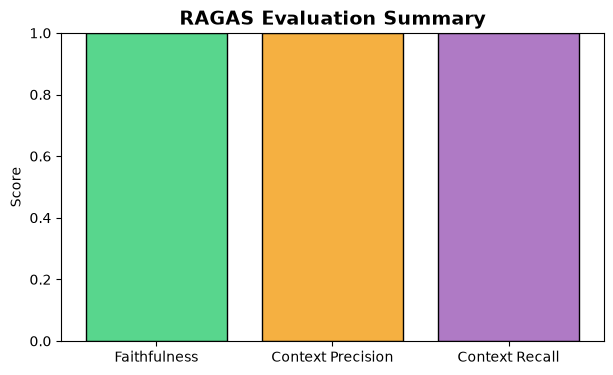

In [41]:
# Visualize the results
metrics = {
    "Answer Relevancy": results["answer_relevancy"],
    "Faithfulness": results["faithfulness"],
    "Context Precision": results["context_precision"],
    "Context Recall": results["context_recall"]
}

plt.figure(figsize=(7, 4))
plot_values = [
    float(pd.Series(value).mean()) if isinstance(value, (list, tuple)) else float(value)
    for value in metrics.values()
]

plt.bar(
    list(metrics.keys()),
    plot_values,
    color=["#5DADE2", "#58D68D", "#F5B041", "#AF7AC5"],
    edgecolor="black"
)
plt.title("RAGAS Evaluation Summary", fontsize=14, fontweight='bold')
plt.ylabel("Score")
plt.ylim(0, 1)
plt.show()

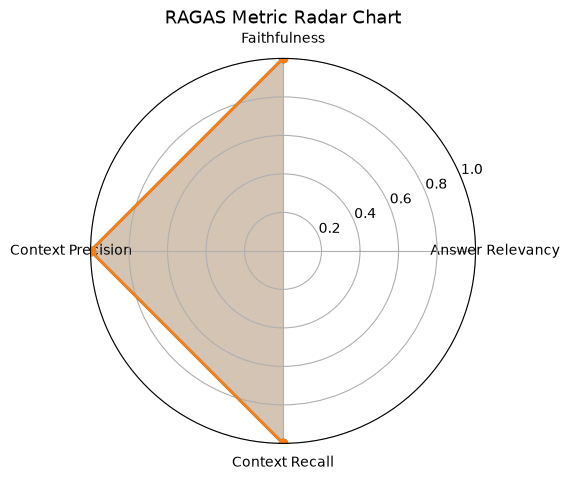

In [42]:
# Radar Chart
import numpy as np

labels = list(metrics.keys())
values = list(metrics.values())
values += values[:1]
angles = np.linspace(0, 2 * np.pi, len(labels) + 1)

plt.figure(figsize=(5, 5))
ax = plt.subplot(111, polar=True)
ax.plot(angles, values, 'o-', linewidth=2)
ax.fill(angles, values, alpha=0.25)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
plt.title("RAGAS Metric Radar Chart", size=13)
plt.show()